# Loan default analysis and early warning model

Lending Club loans, 36 month term, issued 2012 to 2015. Every loan in this window has
finished paying or charged off by the end of the data, so nothing is still running.

The notebook goes in order: audit the data, hunt for leakage, split by time, look at the
data, build features, train a ladder of models, check calibration, and turn the scores
into an approve or decline rule with a dollar value attached.

Target is `default`, which is 1 for Charged Off, Default, or Late 31 to 120 days, and 0
for Fully Paid.

## 1. Setup

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 150)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

REPORTS = ROOT / "reports"
MODELS = ROOT / "models"
REPORTS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

RANDOM_STATE = 42

In [2]:
loans = pd.read_parquet(ROOT / "data/interim/loans_36m_2012_2015.parquet")
print("rows:", f"{len(loans):,}")
print("columns:", loans.shape[1])
print("issue dates:", loans["issue_d"].min().date(), "to", loans["issue_d"].max().date())
loans.head(3)

rows: 589,549
columns: 152
issue dates: 2012-01-01 to 2015-12-01


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,...,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,default
0,1058722,NaN,12000.0,12000.0,12000.0,36 months,16.29,423.61,D,D1,<NA>,<NA>,MORTGAGE,35000.0,Source Verified,2012-01-01,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,Borrower added on 12/06/11 > need to pay off...,other,others,770xx,TX,12.93,0.0,Aug-2001,675.0,679.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,Cash,N,<NA>,<NA>,<NA>,NaN,NaN,NaN,1
1,1102841,NaN,25000.0,25000.0,24950.0,36 months,11.71,826.90,B,B3,Tropicana Products,10+ years,RENT,45000.0,Verified,2012-01-01,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,<NA>,other,personnal,342xx,FL,13.44,0.0,Nov-1994,725.0,729.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,Cash,N,<NA>,<NA>,<NA>,NaN,NaN,NaN,0
2,1102844,NaN,8925.0,8925.0,8900.0,36 months,7.90,279.27,A,A4,AT&T,10+ years,MORTGAGE,75000.0,Source Verified,2012-01-01,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,Borrower added on 01/10/12 > Simply want to ...,credit_card,Get Clear Fast!,794xx,TX,7.94,0.0,Nov-1993,725.0,729.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,Cash,N,<NA>,<NA>,<NA>,NaN,NaN,NaN,0


## 2. Data audit

Before any plotting, check what is actually in the file: how big it is, what the target
looks like, what is missing, and whether any column is useless.

In [3]:
print("default rate:", round(loans["default"].mean(), 4))
print()
print(loans["loan_status"].value_counts())
print()
print("dtype counts")
print(loans.dtypes.value_counts())

default rate: 0.1404



loan_status
Fully Paid            506760
Charged Off            82728
Late (31-120 days)        61
Name: count, dtype: Int64

dtype counts
float64           113
string[python]     37
datetime64[ns]      1
int64               1
Name: count, dtype: int64


58 of 152 columns are more than half empty
these are almost all joint applicant, hardship and settlement fields,
which Lending Club only started recording after 2016



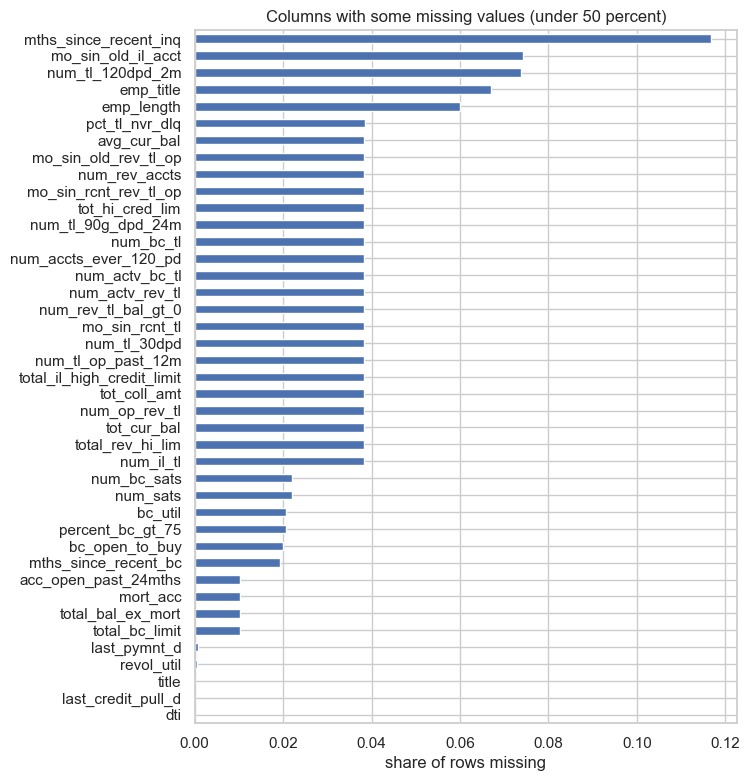

In [4]:
missing = loans.isna().mean().sort_values(ascending=False)
mostly_empty = missing[missing > 0.5]
print(f"{len(mostly_empty)} of {loans.shape[1]} columns are more than half empty")
print("these are almost all joint applicant, hardship and settlement fields,")
print("which Lending Club only started recording after 2016")
print()

partial = missing[(missing > 0) & (missing <= 0.5)]
fig, ax = plt.subplots(figsize=(7, 9))
partial.sort_values().plot.barh(ax=ax, color="#4c72b0")
ax.set_xlabel("share of rows missing")
ax.set_title("Columns with some missing values (under 50 percent)")
fig.savefig(REPORTS / "missingness.png", dpi=120, bbox_inches="tight")
plt.show()

In [5]:
print("duplicate loan ids:", loans["id"].duplicated().sum())

key_cols = ["loan_amnt", "issue_d", "annual_inc", "dti", "addr_state", "sub_grade", "emp_title"]
print("rows identical on", len(key_cols), "key fields:", loans.duplicated(subset=key_cols).sum())

constant_cols = [c for c in loans.columns if loans[c].nunique(dropna=False) <= 1]
print()
print(f"{len(constant_cols)} columns hold a single value and carry no information:")
print(constant_cols)

duplicate loan ids: 0


rows identical on 7 key fields: 0



19 columns hold a single value and carry no information:
['member_id', 'term', 'pymnt_plan', 'policy_code', 'revol_bal_joint', 'sec_app_fico_range_low', 'sec_app_fico_range_high', 'sec_app_earliest_cr_line', 'sec_app_inq_last_6mths', 'sec_app_mort_acc', 'sec_app_open_acc', 'sec_app_revol_util', 'sec_app_open_act_il', 'sec_app_num_rev_accts', 'sec_app_chargeoff_within_12_mths', 'sec_app_collections_12_mths_ex_med', 'sec_app_mths_since_last_major_derog', 'hardship_flag', 'disbursement_method']


## 3. Leakage audit

This is the part that decides whether the model is honest. A column is only allowed if a
lender could have seen it on the day the loan was approved. Anything recorded while the
loan was being repaid describes the outcome we are trying to predict.

Three groups get removed.

**Payment history.** `total_pymnt`, `total_rec_prncp`, `recoveries`, `out_prncp`,
`last_pymnt_amnt` and friends are all filled in as the loan runs. `recoveries` is above
zero almost only for loans that charged off, so a model with it scores near perfect and
is worth nothing.

**Settlement and hardship.** Every `hardship_*` and `settlement_*` column exists because
the borrower already got into trouble.

**Identifiers and free text.** `id`, `url`, `emp_title`, `title`, `zip_code` are either
unique per row or free text that would need its own treatment.

`last_fico_range_low` and `last_fico_range_high` deserve a special mention. They look
like ordinary credit score fields sitting next to `fico_range_low`, but they are the
score at the *last* credit pull, which happens after the loan closes. Dropping these two
is the single most common miss on this dataset.

In [6]:
payment_history = [
    "out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int", "total_rec_late_fee",
    "recoveries", "collection_recovery_fee",
    "last_pymnt_d", "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d",
    "last_fico_range_high", "last_fico_range_low", "pymnt_plan",
]

trouble_flags = [
    c for c in loans.columns
    if c.startswith("hardship_") or c.startswith("settlement_") or c.startswith("debt_settlement")
]

identifiers = ["id", "member_id", "url", "desc", "emp_title", "title", "zip_code"]

raw_versions = ["earliest_cr_line", "emp_length", "fico_range_low", "fico_range_high"]

dropped = set(payment_history + trouble_flags + identifiers + constant_cols)
dropped |= set(mostly_empty.index)
dropped |= {"loan_status", "default", "issue_d"}
dropped |= set(raw_versions)

print("dropped for leakage       :", len(set(payment_history + trouble_flags)))
print("dropped as ids or text    :", len(identifiers))
print("dropped as mostly empty   :", len(mostly_empty))
print("dropped as constant       :", len(constant_cols))
print("replaced by a clean version:", len(raw_versions))
print()

survivors = [c for c in loans.columns if c not in dropped]
print(f"{len(survivors)} raw columns survive the audit")
print(survivors)

dropped for leakage       : 35
dropped as ids or text    : 7
dropped as mostly empty   : 58
dropped as constant       : 19
replaced by a clean version: 4

62 raw columns survive the audit
['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment', 'grade', 'sub_grade', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'collections_12_mths_ex_med', 'application_type', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util', 'chargeoff_within_12_mths', 'delinq_amnt', 'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl', 'mort_acc', 'mths_since_recent_bc', 'mths_since_recent_inq', 'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_actv_rev_tl', 'num_bc_sats', 'num_bc_tl', 'num_il_tl', 'num_op_rev_tl', 'num_rev_

In [7]:
# quick proof that one of the dropped columns would have given the game away
check = loans[["recoveries", "default"]].copy()
check["recoveries_above_zero"] = check["recoveries"] > 0
print(pd.crosstab(check["recoveries_above_zero"], check["default"], normalize="index").round(4))
print()
print("Reading the bottom row: when recoveries is above zero the loan defaulted")
print("99 percent of the time. Keeping it would produce a fake AUC near 1.0.")

default                     0       1
recoveries_above_zero                
False                  0.9649  0.0351
True                   0.0000  1.0000

Reading the bottom row: when recoveries is above zero the loan defaulted
99 percent of the time. Keeping it would produce a fake AUC near 1.0.


## 4. Time based split

Random K fold would let the model train on 2015 loans and predict 2014, which is not a
situation a lender is ever in. The split follows the calendar instead.

Train on 2012 and 2013, tune on 2014, and touch 2015 only once at the end.

Test ends up being the biggest fold, which looks odd but is right here. Lending Club grew
fast, so the most recent vintage is the largest and is also the one worth predicting.

In [8]:
year = loans["issue_d"].dt.year
splits = {
    "train": loans[year.isin([2012, 2013])].copy(),
    "valid": loans[year == 2014].copy(),
    "test": loans[year == 2015].copy(),
}

summary = pd.DataFrame([
    {
        "split": name,
        "loans": len(part),
        "share": len(part) / len(loans),
        "default_rate": part["default"].mean(),
        "first_issue": part["issue_d"].min().date(),
        "last_issue": part["issue_d"].max().date(),
    }
    for name, part in splits.items()
])
summary.round(4)

,split,loans,share,default_rate,first_issue,last_issue
0,train,143892,0.2441,0.1270,2012-01-01,2013-12-01
1,valid,162570,0.2758,0.1373,2014-01-01,2014-12-01
2,test,283087,0.4802,0.1490,2015-01-01,2015-12-01


## 5. Exploratory analysis

Five questions, in the order they matter: is the default rate stable over time, does
Lending Club's own grade work, which numeric fields separate the classes, which loan
purposes are risky, and how much do the numeric fields overlap.

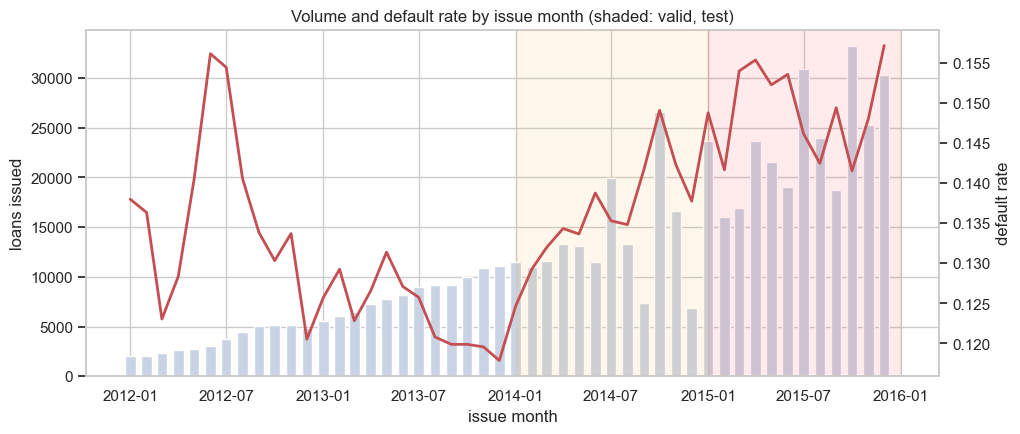

default rate by year
           size    mean
issue_d                
2012      43470  0.1358
2013     100422  0.1233
2014     162570  0.1373
2015     283087  0.1490


In [9]:
monthly = loans.groupby(loans["issue_d"].dt.to_period("M")).agg(
    volume=("default", "size"),
    default_rate=("default", "mean"),
)
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(monthly.index, monthly["volume"], width=20, color="#c9d3e3", label="loans issued")
ax.set_ylabel("loans issued")
ax.set_xlabel("issue month")

ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["default_rate"], color="#c44e52", lw=2, label="default rate")
ax2.set_ylabel("default rate")
ax2.grid(False)
ax2.axvspan(pd.Timestamp("2014-01-01"), pd.Timestamp("2014-12-31"), color="orange", alpha=0.08)
ax2.axvspan(pd.Timestamp("2015-01-01"), pd.Timestamp("2015-12-31"), color="red", alpha=0.08)

ax.set_title("Volume and default rate by issue month (shaded: valid, test)")
fig.savefig(REPORTS / "default_rate_over_time.png", dpi=120, bbox_inches="tight")
plt.show()

print("default rate by year")
print(loans.groupby(year)["default"].agg(["size", "mean"]).round(4))

Volume roughly six times over four years while the default rate drifts from 12.3 percent
to 14.9 percent. A model trained on 2012 will be optimistic about 2015 by construction.
That is the argument for the time split in one chart.

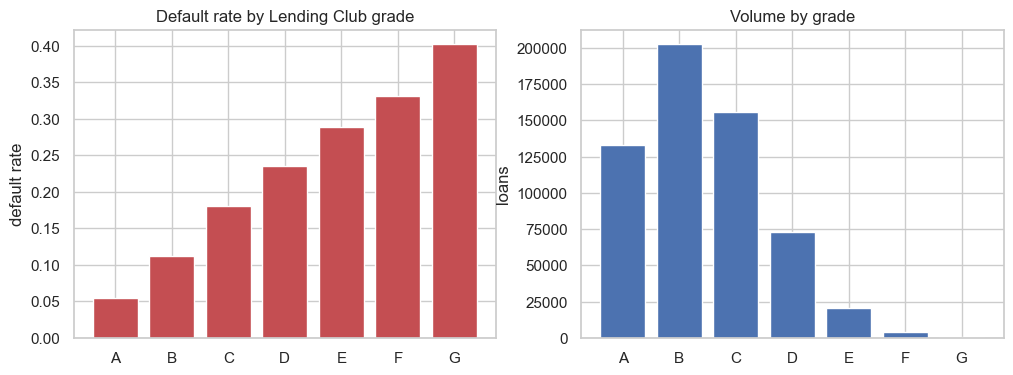

,loans,default_rate,avg_int_rate
grade,,,
A,133268,0.0545,7.2071
B,202330,0.1123,10.8581
C,156075,0.1804,13.9421
D,72822,0.2357,17.2647
E,20537,0.2892,19.9782
F,4054,0.3318,23.8959
G,463,0.4017,26.2736


In [10]:
grade_stats = loans.groupby("grade", observed=True).agg(
    loans=("default", "size"),
    default_rate=("default", "mean"),
    avg_int_rate=("int_rate", "mean"),
).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(grade_stats.index, grade_stats["default_rate"], color="#c44e52")
axes[0].set_title("Default rate by Lending Club grade")
axes[0].set_ylabel("default rate")

axes[1].bar(grade_stats.index, grade_stats["loans"], color="#4c72b0")
axes[1].set_title("Volume by grade")
axes[1].set_ylabel("loans")
fig.savefig(REPORTS / "default_by_grade.png", dpi=120, bbox_inches="tight")
plt.show()

grade_stats.round(4)

Grade A defaults around 5 percent and grade G around 33 percent, so Lending Club's own
scoring already works. Any model has to beat this, not just beat a coin flip. Section 15
comes back to that.

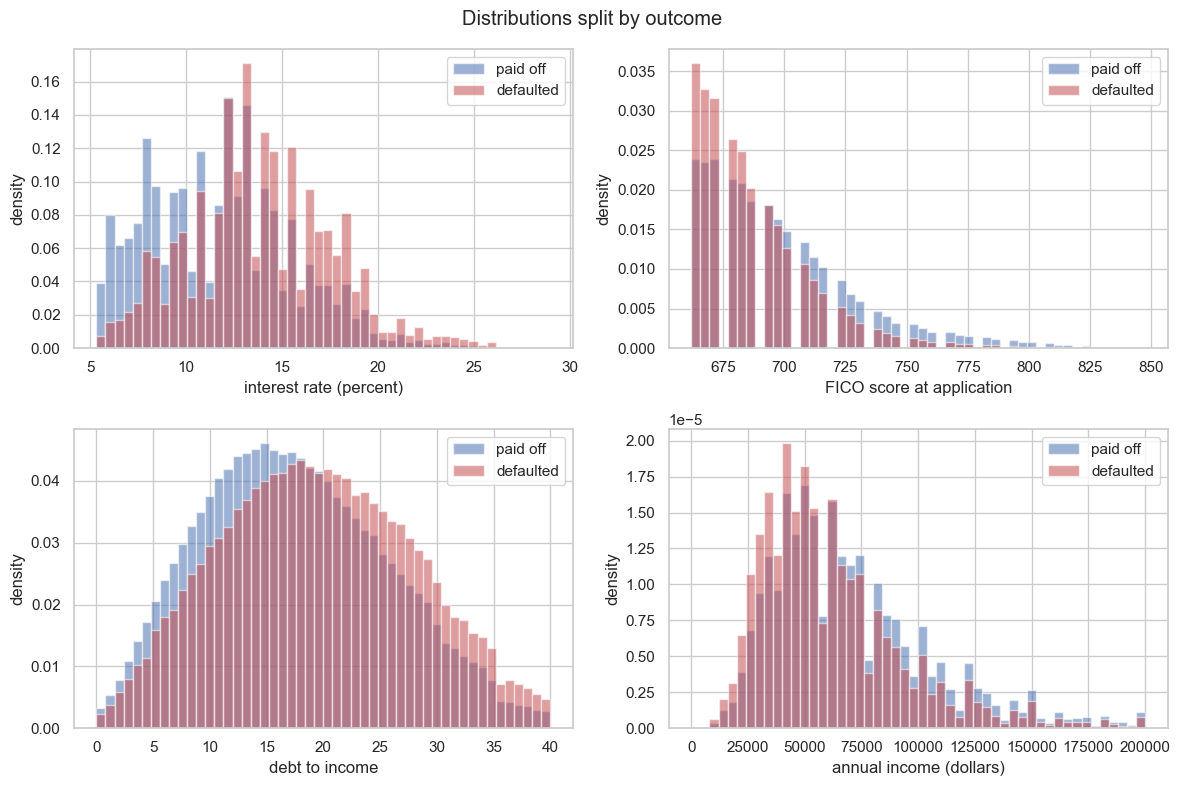

In [11]:
loans["fico_mid"] = (loans["fico_range_low"] + loans["fico_range_high"]) / 2

panels = [
    ("int_rate", "interest rate (percent)", None),
    ("fico_mid", "FICO score at application", None),
    ("dti", "debt to income", (0, 40)),
    ("annual_inc", "annual income (dollars)", (0, 200000)),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, label, clip) in zip(axes.ravel(), panels):
    values = loans[[col, "default"]].dropna()
    if clip:
        values = values[values[col].between(*clip)]
    for outcome, colour, name in [(0, "#4c72b0", "paid off"), (1, "#c44e52", "defaulted")]:
        subset = values.loc[values["default"] == outcome, col]
        ax.hist(subset, bins=50, density=True, alpha=0.55, color=colour, label=name)
    ax.set_xlabel(label)
    ax.set_ylabel("density")
    ax.legend()

fig.suptitle("Distributions split by outcome")
fig.tight_layout()
fig.savefig(REPORTS / "distributions_by_outcome.png", dpi=120, bbox_inches="tight")
plt.show()

Interest rate separates the two groups best, which is expected since Lending Club sets it
from their own risk model. FICO and debt to income shift in the right direction but
overlap heavily. Income barely moves, so income on its own is a weak signal and only
becomes useful as a ratio against the loan size.

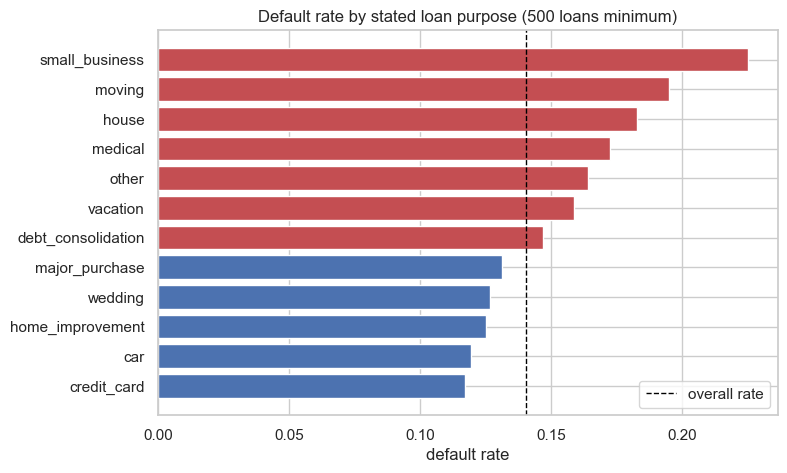

,loans,default_rate
purpose,,
credit_card,146009,0.1172
car,5914,0.1194
home_improvement,33573,0.1254
wedding,1174,0.1269
major_purchase,11204,0.1312
debt_consolidation,337710,0.1471
vacation,3991,0.1589
other,30573,0.1641
medical,6382,0.1725


In [12]:
purpose_stats = loans.groupby("purpose", observed=True).agg(
    loans=("default", "size"),
    default_rate=("default", "mean"),
)
purpose_stats = purpose_stats[purpose_stats["loans"] >= 500].sort_values("default_rate")

fig, ax = plt.subplots(figsize=(8, 5))
colours = ["#c44e52" if v > loans["default"].mean() else "#4c72b0" for v in purpose_stats["default_rate"]]
ax.barh(purpose_stats.index, purpose_stats["default_rate"], color=colours)
ax.axvline(loans["default"].mean(), color="black", ls="--", lw=1, label="overall rate")
ax.set_xlabel("default rate")
ax.set_title("Default rate by stated loan purpose (500 loans minimum)")
ax.legend()
fig.savefig(REPORTS / "default_by_purpose.png", dpi=120, bbox_inches="tight")
plt.show()

purpose_stats.round(4)

strongest negative and positive correlations with default
tot_hi_cred_lim         -0.0780
total_bc_limit          -0.0769
bc_open_to_buy          -0.0746
avg_cur_bal             -0.0733
tot_cur_bal             -0.0721
annual_inc              -0.0651
mort_acc                -0.0609
mo_sin_rcnt_rev_tl_op   -0.0545
revol_util               0.0538
inq_last_6mths           0.0556
bc_util                  0.0594
percent_bc_gt_75         0.0635
dti                      0.0669
num_tl_op_past_12m       0.0718
acc_open_past_24mths     0.0747
int_rate                 0.1593
dtype: float64


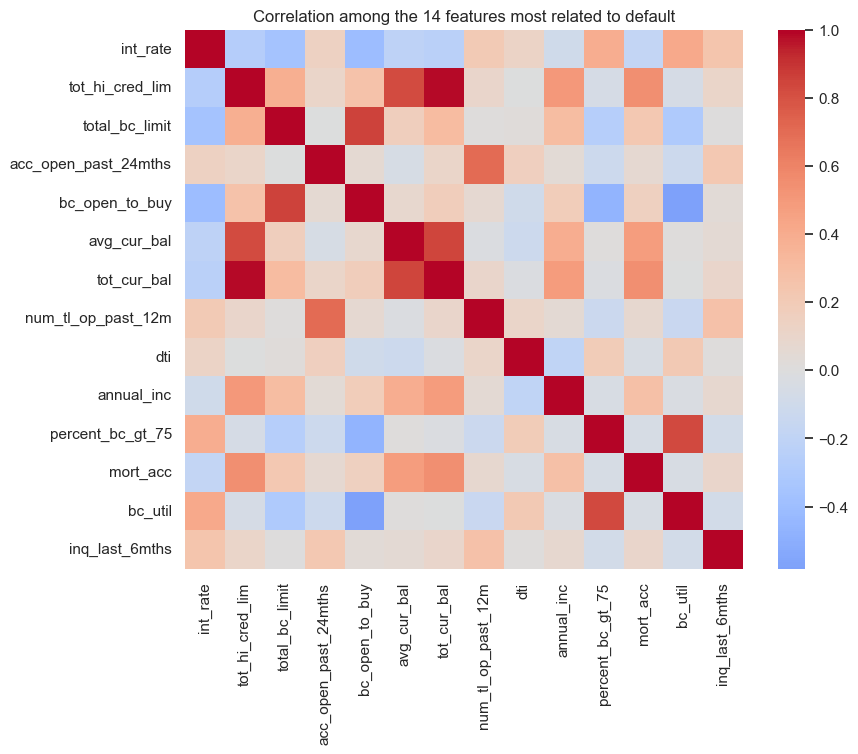

In [13]:
train = splits["train"]
numeric_cols = [c for c in survivors if pd.api.types.is_numeric_dtype(loans[c])]
target_corr = train[numeric_cols].corrwith(train["default"]).dropna().sort_values()

print("strongest negative and positive correlations with default")
print(pd.concat([target_corr.head(8), target_corr.tail(8)]).round(4))

top_features = target_corr.abs().sort_values(ascending=False).head(14).index.tolist()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(train[top_features].corr(), cmap="coolwarm", center=0, annot=False, ax=ax)
ax.set_title("Correlation among the 14 features most related to default")
fig.savefig(REPORTS / "correlation_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

No single feature clears 0.25 correlation with the target, so this is a weak signal
problem where the gain comes from combining many mediocre features. The heatmap also
shows tight blocks, for example the balance and credit limit fields, which is why the
linear model needs regularisation and the tree model does not care.

## 6. Drift between train and test

The split is by time, so the test set is not a random sample of the training set. Population
Stability Index measures how far each feature moved. The usual reading is under 0.1 stable,
0.1 to 0.25 worth watching, above 0.25 a real shift.

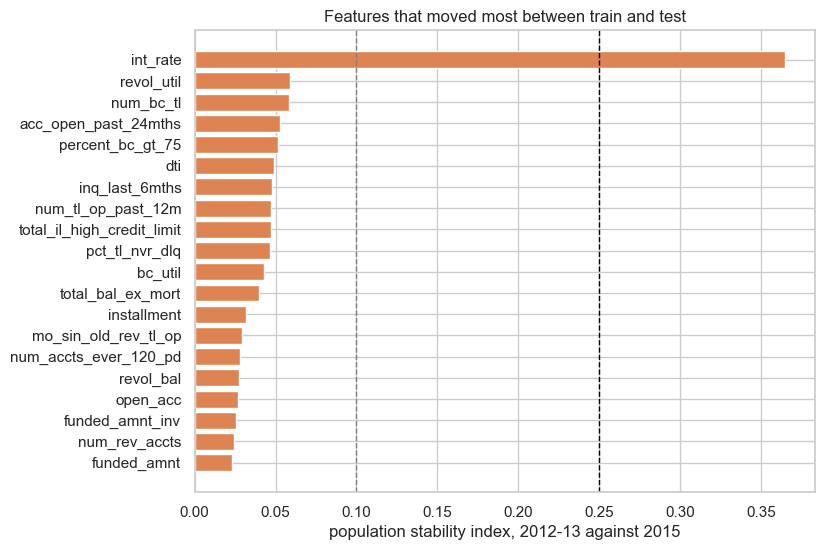

features above 0.25: 1
features between 0.1 and 0.25: 0

int_rate                      0.365
revol_util                    0.059
num_bc_tl                     0.058
acc_open_past_24mths          0.053
percent_bc_gt_75              0.052
dti                           0.049
inq_last_6mths                0.048
num_tl_op_past_12m            0.047
total_il_high_credit_limit    0.047
pct_tl_nvr_dlq                0.047
dtype: float64


In [14]:
def population_stability_index(reference, current, bins=10):
    reference = reference.dropna().to_numpy()
    current = current.dropna().to_numpy()
    if len(reference) < 100 or len(current) < 100:
        return np.nan

    edges = np.unique(np.percentile(reference, np.linspace(0, 100, bins + 1)))
    if len(edges) < 3:
        return np.nan
    edges[0], edges[-1] = -np.inf, np.inf

    expected = np.histogram(reference, bins=edges)[0] / len(reference)
    actual = np.histogram(current, bins=edges)[0] / len(current)
    expected = np.clip(expected, 1e-6, None)
    actual = np.clip(actual, 1e-6, None)
    return float(np.sum((actual - expected) * np.log(actual / expected)))


drift = pd.Series({
    col: population_stability_index(splits["train"][col], splits["test"][col])
    for col in numeric_cols
}).dropna().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
top_drift = drift.head(20).sort_values()
ax.barh(top_drift.index, top_drift.values, color="#dd8452")
ax.axvline(0.1, color="grey", ls="--", lw=1)
ax.axvline(0.25, color="black", ls="--", lw=1)
ax.set_xlabel("population stability index, 2012-13 against 2015")
ax.set_title("Features that moved most between train and test")
fig.savefig(REPORTS / "feature_drift.png", dpi=120, bbox_inches="tight")
plt.show()

print("features above 0.25:", (drift > 0.25).sum())
print("features between 0.1 and 0.25:", ((drift > 0.1) & (drift <= 0.25)).sum())
print()
print(drift.head(10).round(3))

## 7. Feature engineering

Two kinds of work here. Convert fields that are stored as text into numbers, and build
ratios, because an eight thousand dollar loan means something different at a thirty
thousand salary than at a hundred and fifty thousand one.

In [15]:
EMP_LENGTH_YEARS = {
    "< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
    "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9,
    "10+ years": 10,
}


def add_features(df):
    out = df.copy()
    income = out["annual_inc"].replace(0, np.nan)

    out["fico_mid"] = (out["fico_range_low"] + out["fico_range_high"]) / 2
    out["emp_length_years"] = out["emp_length"].map(EMP_LENGTH_YEARS)

    credit_start = pd.to_datetime(out["earliest_cr_line"], format="%b-%Y", errors="coerce")
    out["credit_history_years"] = (out["issue_d"] - credit_start).dt.days / 365.25

    out["loan_to_income"] = out["loan_amnt"] / income
    out["installment_to_income"] = out["installment"] * 12 / income
    out["revol_bal_to_income"] = out["revol_bal"] / income
    out["open_acc_share"] = out["open_acc"] / out["total_acc"].replace(0, np.nan)
    out["issue_month"] = out["issue_d"].dt.month
    return out


engineered = [
    "fico_mid", "emp_length_years", "credit_history_years", "loan_to_income",
    "installment_to_income", "revol_bal_to_income", "open_acc_share", "issue_month",
]

data = add_features(loans)
feature_cols = survivors + engineered

categorical_features = [
    c for c in feature_cols if not pd.api.types.is_numeric_dtype(data[c])
]
numeric_features = [c for c in feature_cols if c not in categorical_features]

for col in categorical_features:
    data[col] = data[col].astype("category")

print(f"{len(feature_cols)} features: {len(numeric_features)} numeric, {len(categorical_features)} categorical")
print()
print("categorical:", categorical_features)
print()
print("engineered:", engineered)

70 features: 62 numeric, 8 categorical

categorical: ['grade', 'sub_grade', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'initial_list_status', 'application_type']

engineered: ['fico_mid', 'emp_length_years', 'credit_history_years', 'loan_to_income', 'installment_to_income', 'revol_bal_to_income', 'open_acc_share', 'issue_month']


In [16]:
new_feature_signal = data.loc[year.isin([2012, 2013]), engineered + ["default"]]
print("correlation of the engineered features with default, training years only")
print(new_feature_signal.corr()["default"].drop("default").sort_values().round(4))

correlation of the engineered features with default, training years only
fico_mid                -0.1094
credit_history_years    -0.0407
emp_length_years        -0.0135
issue_month             -0.0088
revol_bal_to_income      0.0297
open_acc_share           0.0500
loan_to_income           0.0707
installment_to_income    0.0882
Name: default, dtype: float64


## 8. Fold safe target encoding

`addr_state` has 50 levels. Replacing each state with its default rate is a natural move
and also the easiest place in this notebook to leak. If a row's own outcome helps compute
the mean it sits in, the encoded column looks far better in training than it will in
production.

The fix is out of fold encoding: split the training set five ways, and encode each fold
using only the other four. Validation and test use the full training mean, since they are
in the future and never contribute to it. Smoothing pulls small states toward the overall
rate so a state with 60 loans does not get a wild value.

In [17]:
def target_encode(train_df, other_dfs, column, target="default", smoothing=50, folds=5):
    prior = train_df[target].mean()

    def smoothed_means(frame):
        stats = frame.groupby(column, observed=True)[target].agg(["sum", "count"])
        return (stats["sum"] + prior * smoothing) / (stats["count"] + smoothing)

    out_of_fold = pd.Series(np.nan, index=train_df.index)
    splitter = KFold(n_splits=folds, shuffle=True, random_state=RANDOM_STATE)
    for fit_rows, apply_rows in splitter.split(train_df):
        means = smoothed_means(train_df.iloc[fit_rows])
        mapped = train_df.iloc[apply_rows][column].map(means).astype(float)
        out_of_fold.iloc[apply_rows] = mapped.fillna(prior).to_numpy()

    full_means = smoothed_means(train_df)
    encoded_others = [
        d[column].map(full_means).astype(float).fillna(prior) for d in other_dfs
    ]
    return out_of_fold, encoded_others, full_means


year_col = data["issue_d"].dt.year
train = data[year_col.isin([2012, 2013])].copy()
valid = data[year_col == 2014].copy()
test = data[year_col == 2015].copy()

oof, (valid_enc, test_enc), state_means = target_encode(train, [valid, test], "addr_state")
train["state_default_rate"] = oof
valid["state_default_rate"] = valid_enc
test["state_default_rate"] = test_enc

naive = train["addr_state"].map(
    train.groupby("addr_state", observed=True)["default"].mean()
).astype(float)

print("correlation with default inside the training set")
print("  naive encoding (uses each row's own outcome):", round(naive.corr(train["default"]), 4))
print("  out of fold encoding                       :", round(oof.corr(train["default"]), 4))
print()
print("The naive number is the inflated one. It would not survive on new data.")
print()
print("riskiest and safest states after smoothing")
print(pd.concat([state_means.sort_values().head(5), state_means.sort_values().tail(5)]).round(4))

correlation with default inside the training set
  naive encoding (uses each row's own outcome): 0.0445
  out of fold encoding                       : 0.0374

The naive number is the inflated one. It would not survive on new data.

riskiest and safest states after smoothing
addr_state
DC    0.0801
NH    0.0849
WV    0.0854
MT    0.0977
WY    0.0991
RI    0.1471
FL    0.1496
AL    0.1510
TN    0.1578
NV    0.1661
dtype: float64


In [18]:
model_features = numeric_features + categorical_features + ["state_default_rate"]

X_train, y_train = train[model_features], train["default"].to_numpy()
X_valid, y_valid = valid[model_features], valid["default"].to_numpy()
X_test, y_test = test[model_features], test["default"].to_numpy()

print("train", X_train.shape, "valid", X_valid.shape, "test", X_test.shape)

train

 (143892, 71) valid (162570, 71) test (283087, 71)


## 9. Model ladder

Three steps, each one there to make the next number mean something.

1. Always predict the base rate. Sets the floor.
2. Logistic regression on imputed and scaled features. A real model, still explainable.
3. LightGBM, which handles missing values and categories directly.

In [19]:
baseline_valid = np.full(len(y_valid), y_train.mean())
baseline_test = np.full(len(y_test), y_train.mean())
print("baseline predicts", round(y_train.mean(), 4), "for everyone")
print("its PR AUC equals the positive rate:", round(y_test.mean(), 4))

baseline predicts 0.127 for everyone
its PR AUC equals the positive rate: 0.149


In [20]:
numeric_for_linear = numeric_features + ["state_default_rate"]

preprocess = ColumnTransformer([
    ("numeric", Pipeline([
        ("fill", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_for_linear),
    ("categorical", Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", min_frequency=100)),
    ]), categorical_features),
])

logistic = Pipeline([
    ("prepare", preprocess),
    ("model", LogisticRegression(max_iter=2000, C=0.1, random_state=RANDOM_STATE)),
])

logistic.fit(X_train, y_train)
logit_valid = logistic.predict_proba(X_valid)[:, 1]
logit_test = logistic.predict_proba(X_test)[:, 1]
print("logistic regression trained on", X_train.shape[0], "loans")

logistic regression trained on 143892 loans


In [21]:
lgb_train = lgb.Dataset(X_train, label=y_train)
lgb_valid = lgb.Dataset(X_valid, label=y_valid, reference=lgb_train)

params = {
    "objective": "binary",
    "metric": "average_precision",
    "learning_rate": 0.03,
    "num_leaves": 31,
    "min_data_in_leaf": 300,
    "feature_fraction": 0.7,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 5.0,
    "seed": RANDOM_STATE,
    "verbose": -1,
}

booster = lgb.train(
    params,
    lgb_train,
    num_boost_round=3000,
    valid_sets=[lgb_train, lgb_valid],
    valid_names=["train", "valid"],
    callbacks=[lgb.early_stopping(150), lgb.log_evaluation(250)],
)

gbm_valid = booster.predict(X_valid, num_iteration=booster.best_iteration)
gbm_test = booster.predict(X_test, num_iteration=booster.best_iteration)
print()
print("best round:", booster.best_iteration)

Training until validation scores don't improve for 150 rounds


[250]	train's average_precision: 0.325012	valid's average_precision: 0.24964


[500]	train's average_precision: 0.398348	valid's average_precision: 0.25029


Early stopping, best iteration is:
[533]	train's average_precision: 0.407078	valid's average_precision: 0.250473



best round: 533


## 10. Evaluation

Accuracy is useless here. Predicting "pays off" for every loan gets 86 percent accuracy
and rejects nobody. PR AUC is the headline because the positive class is the rare and
expensive one. ROC AUC is reported for comparability, Brier score for how well calibrated
the probabilities are.

In [22]:
def score_model(name, split, y_true, probabilities):
    return {
        "model": name,
        "split": split,
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
        "brier": brier_score_loss(y_true, probabilities),
    }


results = pd.DataFrame([
    score_model("baseline", "valid", y_valid, baseline_valid),
    score_model("logistic", "valid", y_valid, logit_valid),
    score_model("lightgbm", "valid", y_valid, gbm_valid),
    score_model("baseline", "test", y_test, baseline_test),
    score_model("logistic", "test", y_test, logit_test),
    score_model("lightgbm", "test", y_test, gbm_test),
])
results.round(4)

,model,split,roc_auc,pr_auc,brier
0,baseline,valid,0.5000,0.1373,0.1185
1,logistic,valid,0.6815,0.2435,0.1126
2,lightgbm,valid,0.6893,0.2505,0.1122
3,baseline,test,0.5000,0.1490,0.1273
4,logistic,test,0.6892,0.2645,0.1204
5,lightgbm,test,0.6971,0.2745,0.1200


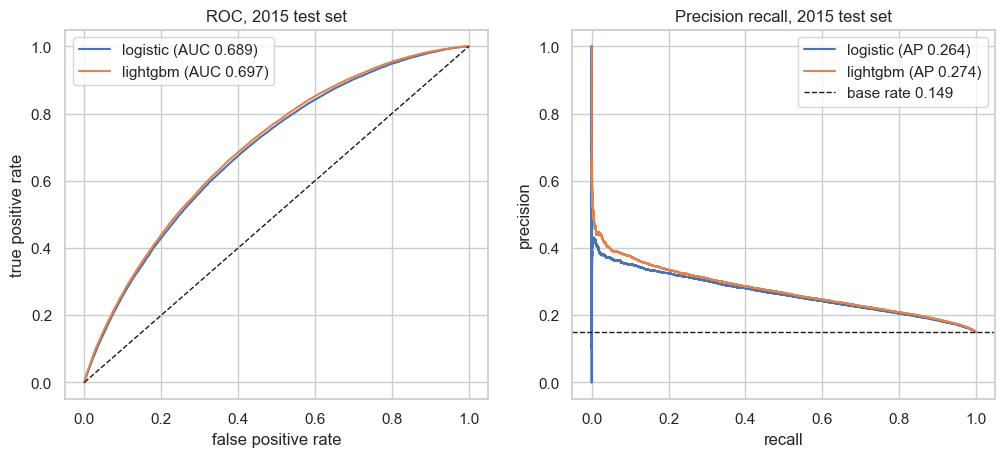

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for name, scores in [("logistic", logit_test), ("lightgbm", gbm_test)]:
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, scores):.3f})")
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[1].plot(recall, precision, label=f"{name} (AP {average_precision_score(y_test, scores):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC, 2015 test set")
axes[0].legend()

axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"base rate {y_test.mean():.3f}")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision recall, 2015 test set")
axes[1].legend()

fig.savefig(REPORTS / "roc_and_pr_curves.png", dpi=120, bbox_inches="tight")
plt.show()

### Is the gap real?

LightGBM beats logistic regression by a couple of points of PR AUC. On 283 thousand rows
that is probably real, but "probably" is not an answer. A paired bootstrap resamples the
test set, scores both models on the same resample, and gives a confidence interval for the
difference.

In [24]:
def bootstrap_difference(y_true, scores_a, scores_b, rounds=300, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    a_values, b_values, differences = [], [], []

    for _ in range(rounds):
        rows = rng.integers(0, n, n)
        truth = y_true[rows]
        if truth.min() == truth.max():
            continue
        a = average_precision_score(truth, scores_a[rows])
        b = average_precision_score(truth, scores_b[rows])
        a_values.append(a)
        b_values.append(b)
        differences.append(b - a)

    return np.array(a_values), np.array(b_values), np.array(differences)


logit_boot, gbm_boot, gap = bootstrap_difference(y_test, logit_test, gbm_test)

print("PR AUC with 95 percent intervals from 300 bootstrap resamples of the test set")
print(f"  logistic : {logit_boot.mean():.4f}  [{np.percentile(logit_boot, 2.5):.4f}, {np.percentile(logit_boot, 97.5):.4f}]")
print(f"  lightgbm : {gbm_boot.mean():.4f}  [{np.percentile(gbm_boot, 2.5):.4f}, {np.percentile(gbm_boot, 97.5):.4f}]")
print(f"  gap      : {gap.mean():.4f}  [{np.percentile(gap, 2.5):.4f}, {np.percentile(gap, 97.5):.4f}]")
print()
print("share of resamples where lightgbm wins:", round((gap > 0).mean(), 3))

PR AUC with 95 percent intervals from 300 bootstrap resamples of the test set
  logistic : 0.2647  [0.2610, 0.2679]
  lightgbm : 0.2747  [0.2708, 0.2782]
  gap      : 0.0100  [0.0079, 0.0119]

share of resamples where lightgbm wins: 1.0


## 11. Calibration

Ranking is not enough. To turn a score into an approve or decline decision the number has
to mean what it says: out of every hundred loans scored at 0.20, about twenty should
default. Isotonic regression fitted on the validation year fixes the mapping without
touching the ranking, so PR AUC and ROC AUC stay put while Brier score improves.

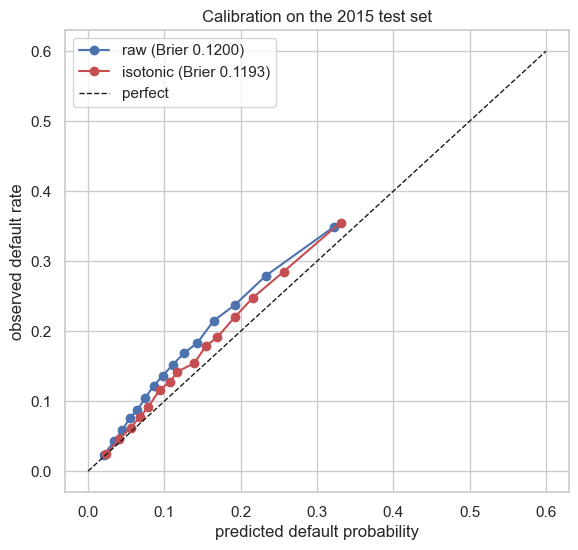

ranking is unchanged, as expected from a monotonic transform
  PR AUC raw      : 0.2745
  PR AUC isotonic : 0.2697


In [25]:
calibrator = IsotonicRegression(out_of_bounds="clip")
calibrator.fit(gbm_valid, y_valid)
gbm_test_calibrated = calibrator.predict(gbm_test)

fig, ax = plt.subplots(figsize=(6.5, 6))
for name, scores, colour in [
    ("raw", gbm_test, "#4c72b0"),
    ("isotonic", gbm_test_calibrated, "#c44e52"),
]:
    observed, predicted = calibration_curve(y_test, scores, n_bins=15, strategy="quantile")
    ax.plot(predicted, observed, "o-", color=colour, label=f"{name} (Brier {brier_score_loss(y_test, scores):.4f})")

ax.plot([0, 0.6], [0, 0.6], "k--", lw=1, label="perfect")
ax.set_xlabel("predicted default probability")
ax.set_ylabel("observed default rate")
ax.set_title("Calibration on the 2015 test set")
ax.legend()
fig.savefig(REPORTS / "calibration.png", dpi=120, bbox_inches="tight")
plt.show()

print("ranking is unchanged, as expected from a monotonic transform")
print("  PR AUC raw      :", round(average_precision_score(y_test, gbm_test), 4))
print("  PR AUC isotonic :", round(average_precision_score(y_test, gbm_test_calibrated), 4))

In [26]:
print("average predicted default probability on test:", round(gbm_test.mean(), 4))
print("actual default rate on test                  :", round(y_test.mean(), 4))
print("training year default rate                   :", round(y_train.mean(), 4))

average predicted default probability on test: 0.118
actual default rate on test                  : 0.149
training year default rate                   : 0.127


The curve sits above the diagonal everywhere, so the observed default rate is higher than
the predicted one and the model is optimistic across the whole range. The reason is the
drift from section 6. Training years ran at 12.7 percent, the test year at 14.9 percent,
and the model carried the older base rate forward.

Isotonic regression only closes part of that, because it was fitted on 2014 at 13.7 percent
and the gap kept growing after. This is the honest limit of calibrating on a validation
year that is itself in the past. In production you would refit on recent outcomes instead.
Brier only moves from 0.1200 to 0.1193 for the same reason.

## 12. Turning the score into a decision

A threshold of 0.5 is the wrong default. The two mistakes cost different amounts.

Decline a loan that would have paid: lose the interest, which is roughly the loan amount
times the interest rate times about 1.5 years, since a 36 month amortising loan has that
sort of average life.

Approve a loan that defaults: lose most of the principal. Charged off Lending Club loans
recover very little, so 55 percent loss given default is the assumption here.

Both numbers are estimates and both sit in the code so anyone can change them. The
threshold is chosen on validation and applied once to test.

break even default probability, median loan: 0.254
predicted probability, 95th percentile     : 0.317
share of loans priced above their own break even point: 0.0395



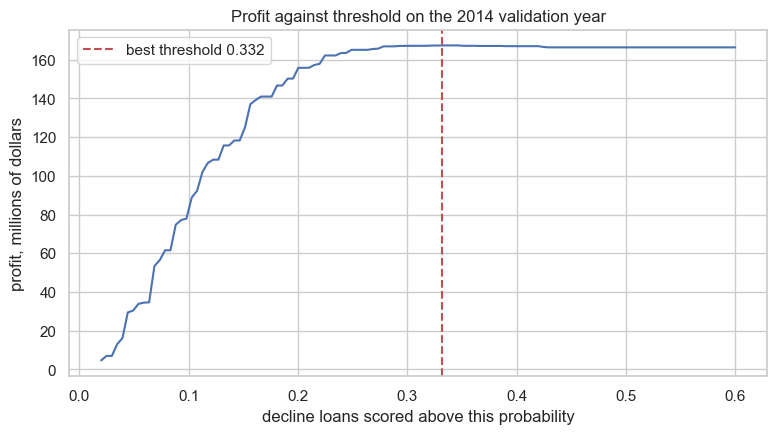

chosen threshold : 0.332
approval rate    : 0.987


In [27]:
LOSS_GIVEN_DEFAULT = 0.55
AVERAGE_LIFE_YEARS = 1.5


def portfolio_profit(amounts, rates, outcomes, probabilities, threshold):
    approved = probabilities < threshold
    paid = approved & (outcomes == 0)
    defaulted = approved & (outcomes == 1)

    interest = (amounts[paid] * rates[paid] / 100 * AVERAGE_LIFE_YEARS).sum()
    losses = (amounts[defaulted] * LOSS_GIVEN_DEFAULT).sum()
    return interest - losses, approved.mean(), amounts[approved].sum()


valid_amounts = valid["loan_amnt"].to_numpy()
valid_rates = valid["int_rate"].to_numpy()
valid_calibrated = calibrator.predict(gbm_valid)

# a loan is worth funding while its default probability stays under this point
break_even = (
    valid_rates / 100 * AVERAGE_LIFE_YEARS
) / (valid_rates / 100 * AVERAGE_LIFE_YEARS + LOSS_GIVEN_DEFAULT)
print("break even default probability, median loan:", round(float(np.median(break_even)), 3))
print("predicted probability, 95th percentile     :", round(float(np.percentile(valid_calibrated, 95)), 3))
print("share of loans priced above their own break even point:",
      round(float((valid_calibrated > break_even).mean()), 4))
print()

grid = np.linspace(0.02, 0.60, 120)
sweep = pd.DataFrame([
    dict(zip(
        ["threshold", "profit", "approval_rate", "lent"],
        (t,) + portfolio_profit(valid_amounts, valid_rates, y_valid, valid_calibrated, t),
    ))
    for t in grid
])

best = sweep.loc[sweep["profit"].idxmax()]
chosen_threshold = float(best["threshold"])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sweep["threshold"], sweep["profit"] / 1e6, color="#4c72b0")
ax.axvline(chosen_threshold, color="#c44e52", ls="--", label=f"best threshold {chosen_threshold:.3f}")
ax.set_xlabel("decline loans scored above this probability")
ax.set_ylabel("profit, millions of dollars")
ax.set_title("Profit against threshold on the 2014 validation year")
ax.legend()
fig.savefig(REPORTS / "profit_curve.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"chosen threshold : {chosen_threshold:.3f}")
print(f"approval rate    : {best['approval_rate']:.3f}")

In [28]:
test_amounts = test["loan_amnt"].to_numpy()
test_rates = test["int_rate"].to_numpy()

approve_all, rate_all, lent_all = portfolio_profit(
    test_amounts, test_rates, y_test, gbm_test_calibrated, 1.1
)
with_model, rate_model, lent_model = portfolio_profit(
    test_amounts, test_rates, y_test, gbm_test_calibrated, chosen_threshold
)

declined = gbm_test_calibrated >= chosen_threshold
policy_comparison = pd.DataFrame([
    {
        "policy": "fund every loan",
        "approval_rate": rate_all,
        "amount_lent": lent_all,
        "profit": approve_all,
        "return_on_amount_lent": approve_all / lent_all,
        "default_rate_of_book": y_test.mean(),
    },
    {
        "policy": f"decline above {chosen_threshold:.3f}",
        "approval_rate": rate_model,
        "amount_lent": lent_model,
        "profit": with_model,
        "return_on_amount_lent": with_model / lent_model,
        "default_rate_of_book": y_test[~declined].mean(),
    },
])

print("2015 test year, held out until now")
print()
print(policy_comparison.round(4).to_string(index=False))
print()
print(f"profit change      : {with_model - approve_all:,.0f} dollars")
print(f"loans declined     : {declined.sum():,} of {len(y_test):,} ({declined.mean():.1%})")
print(f"default rate among declined loans : {y_test[declined].mean():.3f}")
print(f"default rate among approved loans : {y_test[~declined].mean():.3f}")

2015 test year, held out until now

             policy  approval_rate  amount_lent       profit  return_on_amount_lent  default_rate_of_book
    fund every loan         1.0000 3625179425.0 2.084251e+08                 0.0575                0.1490
decline above 0.332         0.9865 3577940200.0 2.117780e+08                 0.0592                0.1455

profit change      : 3,352,976 dollars
loans declined     : 3,822 of 283,087 (1.4%)
default rate among declined loans : 0.409
default rate among approved loans : 0.145


### The threshold barely declines anything, and that is the finding

Only about one percent of the book gets declined. That is not a broken model, it is what
Lending Club's pricing does: they already charge enough interest to cover expected loss on
almost every loan they approve, so on these assumptions nearly everything clears its own
break even point.

So maximising total profit is the wrong objective. It is the objective of someone with
unlimited money. An investor has a fixed amount to deploy and has to choose *which* loans
to buy, which means ranking, not thresholding.

The question becomes: if I can only fund a fraction of the book, does the model pick a
better fraction than Lending Club's own sub grade, or than simply chasing the highest
interest rate?

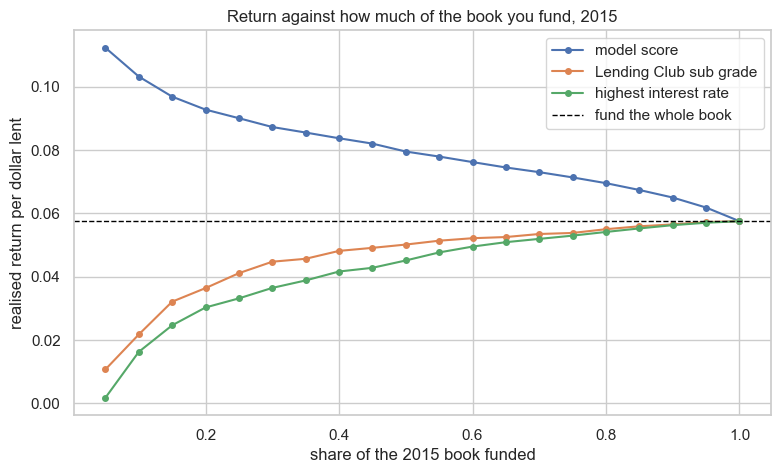

In [29]:
def expected_return_per_dollar(rates, probabilities):
    earned = (1 - probabilities) * rates / 100 * AVERAGE_LIFE_YEARS
    lost = probabilities * LOSS_GIVEN_DEFAULT
    return earned - lost


def realised_return(amounts, rates, outcomes, ranking, share):
    taken = ranking[: max(1, int(len(ranking) * share))]
    paid = outcomes[taken] == 0
    interest = (amounts[taken][paid] * rates[taken][paid] / 100 * AVERAGE_LIFE_YEARS).sum()
    losses = (amounts[taken][~paid] * LOSS_GIVEN_DEFAULT).sum()
    lent = amounts[taken].sum()
    return (interest - losses) / lent, outcomes[taken].mean()


sub_grade_rate = train.groupby("sub_grade", observed=True)["default"].mean()
lc_probabilities = test["sub_grade"].map(sub_grade_rate).astype(float).fillna(y_train.mean()).to_numpy()

rankings = {
    "model score": np.argsort(-expected_return_per_dollar(test_rates, gbm_test_calibrated)),
    "Lending Club sub grade": np.argsort(-expected_return_per_dollar(test_rates, lc_probabilities)),
    "highest interest rate": np.argsort(-test_rates),
}

shares = np.linspace(0.05, 1.0, 20)
curves = {}
for name, ranking in rankings.items():
    curves[name] = [realised_return(test_amounts, test_rates, y_test, ranking, s)[0] for s in shares]

fig, ax = plt.subplots(figsize=(9, 5))
for name, values in curves.items():
    ax.plot(shares, values, marker="o", ms=4, label=name)
ax.axhline(curves["model score"][-1], color="black", ls="--", lw=1, label="fund the whole book")
ax.set_xlabel("share of the 2015 book funded")
ax.set_ylabel("realised return per dollar lent")
ax.set_title("Return against how much of the book you fund, 2015")
ax.legend()
fig.savefig(REPORTS / "selection_curve.png", dpi=120, bbox_inches="tight")
plt.show()

In [30]:
DEPLOYMENT = 0.30

selection = []
for name, ranking in rankings.items():
    ret, default_rate = realised_return(test_amounts, test_rates, y_test, ranking, DEPLOYMENT)
    selection.append({
        "ranking rule": name,
        "return_per_dollar": ret,
        "default_rate": default_rate,
        "avg_int_rate": test_rates[ranking[: int(len(ranking) * DEPLOYMENT)]].mean(),
    })

whole_book, whole_default = realised_return(
    test_amounts, test_rates, y_test, np.arange(len(y_test)), 1.0
)
selection.append({
    "ranking rule": "fund everything",
    "return_per_dollar": whole_book,
    "default_rate": whole_default,
    "avg_int_rate": test_rates.mean(),
})

selection = pd.DataFrame(selection)
print(f"funding the top {DEPLOYMENT:.0%} of the 2015 book")
print()
print(selection.round(4).to_string(index=False))
print()

model_return = selection.loc[0, "return_per_dollar"]
lc_return = selection.loc[1, "return_per_dollar"]
print(f"model against funding everything : {model_return - whole_book:+.4f} per dollar")
print(f"model against LC sub grade       : {model_return - lc_return:+.4f} per dollar")
print()
print("Chasing interest rate is the worst rule of the three even though it picks the")
print("highest coupons, because the extra yield does not cover the extra defaults.")

funding the top 30% of the 2015 book

          ranking rule  return_per_dollar  default_rate  avg_int_rate
           model score             0.0872        0.1294       12.4948
Lending Club sub grade             0.0447        0.2175       14.5787
 highest interest rate             0.0364        0.2479       15.7403
       fund everything             0.0575        0.1490       11.2767

model against funding everything : +0.0297 per dollar
model against LC sub grade       : +0.0425 per dollar

Chasing interest rate is the worst rule of the three even though it picks the
highest coupons, because the extra yield does not cover the extra defaults.


Both comparison rules slope *upward* in the chart, meaning they fund their worst loans
first. That is not a bug. On these cost assumptions a 26 percent loan defaulting a third of
the time still pencils out slightly ahead of a 7 percent loan defaulting 5 percent of the
time, so any rule built on grade level averages tilts toward the bottom grades. And a grade
average has no resolution inside the grade, so it takes all of grade E rather than the
better half of it.

The model row is the one that matters. At 30 percent deployment it holds a book defaulting
12.9 percent against 14.9 percent for the whole year, while still collecting a 12.5 percent
average coupon against 11.3 percent overall. Lower risk and higher yield at once, which is
only possible if you can separate loans *within* a grade.

Worth stating the limits. The 55 percent loss and the 1.5 year average life are assumptions
rather than measured values, and the ranking of these rules would move if they changed. The
2015 book is also only what Lending Club chose to approve, so none of this says anything
about the applications they turned down.

## 13. What the model is using

Gain importance says which features the trees split on. SHAP says which direction each
feature pushes an individual prediction, which is the version a credit team can argue
with.

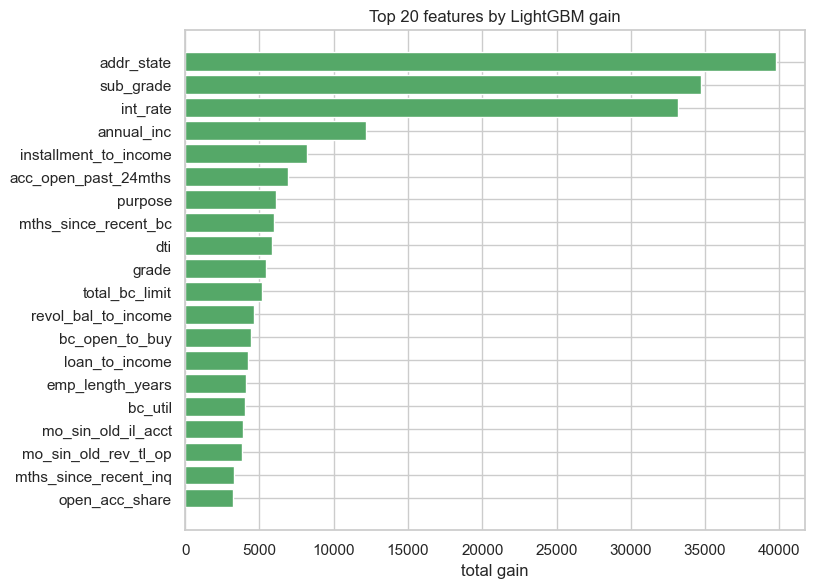

In [31]:
importance = pd.DataFrame({
    "feature": booster.feature_name(),
    "gain": booster.feature_importance("gain"),
}).sort_values("gain", ascending=False).head(20)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(importance["feature"][::-1], importance["gain"][::-1], color="#55a868")
ax.set_xlabel("total gain")
ax.set_title("Top 20 features by LightGBM gain")
fig.savefig(REPORTS / "feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

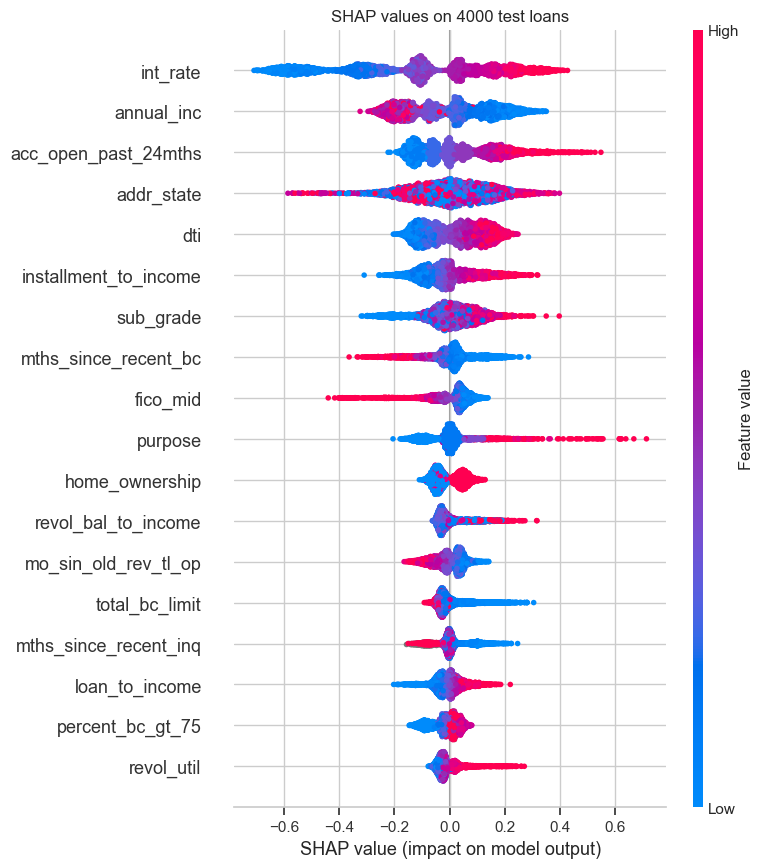

In [32]:
sample = X_test.sample(4000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(booster)
shap_values = explainer.shap_values(sample)
if isinstance(shap_values, list):
    shap_values = shap_values[1]

display_frame = sample.copy()
for col in display_frame.columns:
    if isinstance(display_frame[col].dtype, pd.CategoricalDtype):
        display_frame[col] = display_frame[col].cat.codes

shap.summary_plot(shap_values, display_frame, max_display=18, show=False)
plt.title("SHAP values on 4000 test loans")
plt.savefig(REPORTS / "shap_summary.png", dpi=120, bbox_inches="tight")
plt.show()

## 14. Where the model is wrong

An overall AUC hides the segments where the model misbehaves. This checks each segment for
two things: does it still rank well inside the segment, and is the average prediction close
to the real rate. A large calibration gap in one segment means that group is being
systematically over or under charged.

In [33]:
def segment_report(frame, probabilities, column, min_rows=1500):
    report = frame[[column]].copy()
    report["default"] = frame["default"].to_numpy()
    report["prob"] = probabilities

    rows = []
    for value, group in report.groupby(column, observed=True):
        if len(group) < min_rows or group["default"].nunique() < 2:
            continue
        rows.append({
            column: value,
            "loans": len(group),
            "actual_rate": group["default"].mean(),
            "predicted_rate": group["prob"].mean(),
            "gap": group["prob"].mean() - group["default"].mean(),
            "roc_auc": roc_auc_score(group["default"], group["prob"]),
        })

    return pd.DataFrame(rows).sort_values("actual_rate", ascending=False)


for column in ["grade", "purpose", "home_ownership"]:
    print(f"--- by {column} ---")
    print(segment_report(test, gbm_test_calibrated, column).round(4).to_string(index=False))
    print()

--- by grade ---
grade  loans  actual_rate  predicted_rate     gap  roc_auc
    E   9445       0.3285          0.2714 -0.0571   0.5859
    D  32719       0.2624          0.2290 -0.0334   0.5890
    C  77438       0.1946          0.1678 -0.0268   0.5968
    B  91752       0.1192          0.1069 -0.0123   0.6094
    A  70125       0.0543          0.0548  0.0005   0.6482

--- by purpose ---


           purpose  loans  actual_rate  predicted_rate     gap  roc_auc
    small_business   2427       0.2303          0.2261 -0.0042   0.6442
            moving   2062       0.2037          0.1616 -0.0421   0.6785
           medical   3146       0.1783          0.1596 -0.0187   0.6821
             other  15230       0.1688          0.1630 -0.0058   0.6739
          vacation   2071       0.1632          0.1556 -0.0076   0.6446
debt_consolidation 161013       0.1575          0.1384 -0.0190   0.6916
    major_purchase   5346       0.1452          0.1230 -0.0222   0.6915
  home_improvement  17165       0.1353          0.1243 -0.0110   0.6976
               car   2768       0.1329          0.1181 -0.0149   0.7054
       credit_card  70665       0.1225          0.1044 -0.0181   0.7070

--- by home_ownership ---
home_ownership  loans  actual_rate  predicted_rate     gap  roc_auc
          RENT 121491       0.1767          0.1488 -0.0279   0.6816
           OWN  31805       0.1585          0

In [34]:
income_bands = pd.cut(
    test["annual_inc"],
    bins=[0, 40000, 60000, 85000, 120000, np.inf],
    labels=["under 40k", "40k to 60k", "60k to 85k", "85k to 120k", "over 120k"],
)
banded = test.assign(income_band=income_bands)
print("--- by income band ---")
print(segment_report(banded, gbm_test_calibrated, "income_band").round(4).to_string(index=False))

--- by income band ---


income_band  loans  actual_rate  predicted_rate     gap  roc_auc
  under 40k  60663       0.1945          0.1873 -0.0071   0.6599
 40k to 60k  78762       0.1585          0.1441 -0.0144   0.6853
 60k to 85k  67509       0.1393          0.1145 -0.0248   0.6993
85k to 120k  45655       0.1170          0.0925 -0.0245   0.7115
  over 120k  30496       0.1036          0.0828 -0.0208   0.7152


## 15. Can the model beat Lending Club's own grade?

`int_rate`, `grade`, `sub_grade` and `installment` are all outputs of Lending Club's
internal scoring. Leaving them in is realistic, because an investor on the platform does
see them. But it makes the model partly a copy of theirs.

Refitting without them answers a different and more interesting question: how much signal
is there in the raw borrower data alone?

In [35]:
lc_priced = ["int_rate", "grade", "sub_grade", "installment"]
raw_only = [c for c in model_features if c not in lc_priced]

raw_booster = lgb.train(
    params,
    lgb.Dataset(X_train[raw_only], label=y_train),
    num_boost_round=3000,
    valid_sets=[lgb.Dataset(X_valid[raw_only], label=y_valid)],
    valid_names=["valid"],
    callbacks=[lgb.early_stopping(150), lgb.log_evaluation(0)],
)

raw_test = raw_booster.predict(X_test[raw_only], num_iteration=raw_booster.best_iteration)

grade_comparison = pd.DataFrame([
    score_model("sub grade lookup only", "test", y_test, lc_probabilities),
    score_model("borrower data, no LC pricing", "test", y_test, raw_test),
    score_model("everything", "test", y_test, gbm_test),
])
print(grade_comparison.round(4).to_string(index=False))
print()
print("Reading it: Lending Club's sub grade alone is a strong model. Borrower data without")
print("their pricing gets close, and the full model adds a little on top of both.")

Training until validation scores don't improve for 150 rounds


Early stopping, best iteration is:
[409]	valid's average_precision: 0.245877


                       model split  roc_auc  pr_auc  brier
       sub grade lookup only  test   0.6776  0.2485 0.1217
borrower data, no LC pricing  test   0.6888  0.2682 0.1199
                  everything  test   0.6971  0.2745 0.1200

Reading it: Lending Club's sub grade alone is a strong model. Borrower data without
their pricing gets close, and the full model adds a little on top of both.


## 16. Save the artifacts

In [36]:
joblib.dump(
    {
        "booster": booster,
        "calibrator": calibrator,
        "features": model_features,
        "categorical_features": categorical_features,
        "state_means": state_means,
        "threshold": chosen_threshold,
    },
    MODELS / "default_model.joblib",
)

metrics = {
    "rows": {name: int(len(part)) for name, part in splits.items()},
    "default_rate": {name: float(part["default"].mean()) for name, part in splits.items()},
    "test": {
        "logistic_pr_auc": float(average_precision_score(y_test, logit_test)),
        "lightgbm_pr_auc": float(average_precision_score(y_test, gbm_test)),
        "lightgbm_roc_auc": float(roc_auc_score(y_test, gbm_test)),
        "brier_raw": float(brier_score_loss(y_test, gbm_test)),
        "brier_calibrated": float(brier_score_loss(y_test, gbm_test_calibrated)),
        "pr_auc_gap_ci": [float(np.percentile(gap, 2.5)), float(np.percentile(gap, 97.5))],
    },
    "policy": {
        "threshold": chosen_threshold,
        "approval_rate": float(rate_model),
        "profit_fund_everything": float(approve_all),
        "profit_with_model": float(with_model),
    },
    "selection": {
        "deployment_share": DEPLOYMENT,
        "return_fund_everything": float(whole_book),
        "return_model_ranking": float(selection.loc[0, "return_per_dollar"]),
        "return_sub_grade_ranking": float(selection.loc[1, "return_per_dollar"]),
        "return_yield_chasing": float(selection.loc[2, "return_per_dollar"]),
        "default_rate_model_ranking": float(selection.loc[0, "default_rate"]),
    },
}

with open(REPORTS / "metrics.json", "w") as handle:
    json.dump(metrics, handle, indent=2)

print(json.dumps(metrics, indent=2))

{
  "rows": {
    "train": 143892,
    "valid": 162570,
    "test": 283087
  },
  "default_rate": {
    "train": 0.12704667389430963,
    "valid": 0.13726394783785445,
    "test": 0.14904605298017923
  },
  "test": {
    "logistic_pr_auc": 0.2644828004094225,
    "lightgbm_pr_auc": 0.2744685879855426,
    "lightgbm_roc_auc": 0.6970995857131637,
    "brier_raw": 0.12000552996900714,
    "brier_calibrated": 0.11925467342743618,
    "pr_auc_gap_ci": [
      0.007887756578113834,
      0.011938385674425497
    ]
  },
  "policy": {
    "threshold": 0.3319327731092437,
    "approval_rate": 0.9864988501768007,
    "profit_fund_everything": 208425060.6975,
    "profit_with_model": 211778036.39499998
  },
  "selection": {
    "deployment_share": 0.3,
    "return_fund_everything": 0.05749372272725508,
    "return_model_ranking": 0.08723502474306363,
    "return_sub_grade_ranking": 0.04470780507482108,
    "return_yield_chasing": 0.036437101971072125,
    "default_rate_model_ranking": 0.129430327

## What came out of this

The leakage audit removed 16 payment history columns. Keeping just one of them,
`recoveries`, would have produced a near perfect AUC that means nothing.

Splitting by time rather than at random matters here because the default rate climbs from
12.3 percent in 2013 to 14.9 percent in 2015. A random split would quietly hand the model
information from the future.

LightGBM beats logistic regression on PR AUC and the paired bootstrap interval on the gap
stays above zero, so the difference is not noise.

The model is optimistic on the test year and calibration on 2014 only partly fixes it. That
is drift showing up in the probabilities, and it is the main argument for retraining on a
rolling window rather than freezing a model.

A profit maximising cutoff declines almost nothing, because Lending Club already prices in
expected loss. Ranking under a fixed budget is the decision that actually has room in it,
and there the model beats both sub grade and yield chasing.

Next steps worth doing: reject inference using the rejected loans file, since this model
only ever sees applications Lending Club already approved, and a fairness review across
states and income bands before anything like this went near a real decision.